In [1]:
import json
import subprocess
from datetime import datetime

with open("query_result.json", "r") as f:
    data = json.load(f)


In [2]:
data

{'numberOfRecords': 151,
 'totalNumberOfRecords': 151,
 'records': [{'flare_class': 'M6.6',
   'start_time': '2011-02-13 17:28:00',
   'peak_time': '2011-02-13 17:38:00',
   'end_time': '2011-02-13 17:47:00',
   'active_region_number': 11158,
   'harp_number': 377},
  {'flare_class': 'X2.2',
   'start_time': '2011-02-15 01:44:00',
   'peak_time': '2011-02-15 01:56:00',
   'end_time': '2011-02-15 02:06:00',
   'active_region_number': 11158,
   'harp_number': 377},
  {'flare_class': 'X1.5',
   'start_time': '2011-03-09 23:13:00',
   'peak_time': '2011-03-09 23:23:00',
   'end_time': '2011-03-09 23:29:00',
   'active_region_number': 11166,
   'harp_number': 401},
  {'flare_class': 'M9.3',
   'start_time': '2011-07-30 02:04:00',
   'peak_time': '2011-07-30 02:09:00',
   'end_time': '2011-07-30 02:12:00',
   'active_region_number': 11261,
   'harp_number': 750},
  {'flare_class': 'M6.0',
   'start_time': '2011-08-03 13:17:00',
   'peak_time': '2011-08-03 13:48:00',
   'end_time': '2011-08-0

In [2]:
records = data['records']

m_flares = [
    flare for flare in records if flare["flare_class"].startswith('M')
]

x_flares = [
    flare for flare in records if flare["flare_class"].startswith('X')
]
selected_flares = m_flares[:15] + x_flares[:15]

In [8]:
print(f"M-class available: {len(m_flares)}")
print(f"X-class available: {len(x_flares)}")
print(f"Selected: {len(selected_flares)}")

M-class available: 94
X-class available: 57
Selected: 30


In [3]:
dates = sorted({
    datetime.strptime(
        flare["peak_time"],
        "%Y-%m-%d %H:%M:%S"
    ).strftime("%m/%d/%Y")
    for flare in selected_flares
})

In [22]:
dates

['01/07/2014',
 '01/23/2012',
 '02/13/2011',
 '02/15/2011',
 '03/07/2012',
 '03/09/2011',
 '03/09/2012',
 '03/10/2012',
 '03/29/2014',
 '04/11/2013',
 '04/25/2014',
 '05/10/2012',
 '07/02/2012',
 '07/04/2012',
 '07/05/2012',
 '07/12/2012',
 '07/30/2011',
 '08/03/2011',
 '08/04/2011',
 '09/06/2011',
 '09/07/2011',
 '09/08/2011',
 '09/10/2014',
 '09/25/2011',
 '10/22/2014',
 '10/24/2014',
 '11/08/2013',
 '11/10/2013']

In [ ]:
for date in dates:
    cmd = [
        "globalDownload.py",
        "--verbose",
        "--url=https://cedar.openmadrigal.org/",
        "--outputDir=./tec_hdf5",
        '--user_fullname=Amrit+Madabushi',
        "--user_email=am2699@njit.edu",
        '--user_affiliation=NJIT',
        '--format=hdf5',
        f"--startDate={date}",
        f"--endDate={date}",
        "--inst=8000",
        "--kindat=3500"
    ]
    print(f"Downloading TEC for {date}")
    subprocess.run(cmd, check=True)

Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments4/2014/gps/06jan14
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments4/2014/gps/07jan14
2 files being downloaded
Downloaded file ./tec_hdf5/gps140106g.003_0.hdf5
Downloaded file ./tec_hdf5/gps140107g.003_0.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2012/gps/22jan12
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2012/gps/23jan12
2 files being downloaded
Downloaded file ./tec_hdf5/gps120122g.003.hdf5
Downloaded file ./tec_hdf5/gps120123g.003.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/12feb11
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/13feb11
2 files being downloaded
Downloaded file ./tec_hdf5/gps110212g.002.hdf5
Downloaded file ./tec_hdf5/gps110213g.002.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/14feb11
Analyzed exp url https://cedar.openmadrigal.

In [6]:
import h5py
import pandas as pd
import numpy as np
from pathlib import Path

TEC_DIR = Path("tec_hdf5")
CHUNK_SIZE = 250_000

def get_tec_file(flare):
    """Find the daily TEC file corresponding to a flare's peak date."""
    peak = pd.to_datetime(flare["peak_time"])
    date_code = peak.strftime("%y%m%d")

    # print(date_code)
    matches = sorted(TEC_DIR.glob(f"gps{date_code}g.*.hdf5"))

    if not matches:
        raise FileNotFoundError(
            f"No TEC file found for {peak.date()}"
        )
    return matches[0]

def extract_nearest_tec_map(target_time):
    """
    Find the TEC snapshot nearest to target_time wtihout loading the entire daily HDF5 into memory.
    """
    target_time = pd.to_datetime(target_time)

    #Select HDF5 file based on target_date
    date_code = target_time.strftime("%y%m%d")
    matches = sorted(TEC_DIR.glob(f"gps{date_code}g.*.hdf5"))
    if not matches:
        raise FileNotFoundError(
            f"No TEC file found for {target_time.date()}"
        )
    path = matches[0]

    nearest_time = None
    nearest_diff = None

    # PASS 1: find nearest avaliable TEC timestamp
    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0,len(table),CHUNK_SIZE):
            chunk = table[start:start+CHUNK_SIZE]

            times = pd.to_datetime({
                "year": chunk["year"],
                "month": chunk["month"],
                "day": chunk["day"],
                "hour": chunk["hour"],
                "minute": chunk["min"],
                "second": chunk["sec"],
            })

            unique_times = pd.Index(times.unique())

            diffs = abs(unique_times-target_time)
            i = diffs.argmin()

            candidate_time = unique_times[i]
            candidate_diff = diffs[i]

            if nearest_diff is None or candidate_diff < nearest_diff:
                nearest_diff = candidate_diff
                nearest_time = candidate_time
        print(f"Requested: {target_time}")
    print(f"Nearest TEC map: {nearest_time}")
    print(f"Difference: {nearest_diff}")
    if nearest_diff > pd.Timedelta(minutes=5):
        raise ValueError(
            f"TEC timestamp mismatch: requested {target_time}, nearest {nearest_time}, difference {nearest_diff}"
        )

    # PASS 2: extract only rows belonging to that TEC timestamp
    pieces = []

    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0, len(table), CHUNK_SIZE):
            chunk = table[start:start + CHUNK_SIZE]

            mask = (
                (chunk["year"] == nearest_time.year) &
                (chunk["month"] == nearest_time.month) &
                (chunk["day"] == nearest_time.day) &
                (chunk["hour"] == nearest_time.hour) &
                (chunk["min"] == nearest_time.minute) &
                (chunk["sec"] == nearest_time.second)
            )

            if np.any(mask):
                selected = chunk[mask]

                pieces.append(
                    pd.DataFrame({
                        "gdlat": selected["gdlat"],
                        "glon": selected["glon"],
                        "tec": selected["tec"],
                    })
                )

    if not pieces:
        raise RuntimeError(
            f"No TEC rows found for {nearest_time}"
        )

    tec_map = pd.concat(pieces, ignore_index=True)

    # Madrigal missing-value convention
    tec_map.loc[tec_map["tec"] > 1e20, "tec"] = np.nan

    return nearest_time, tec_map

In [4]:
flare = selected_flares[0]

path = get_tec_file(flare)

print("Flare:", flare["flare_class"], flare["peak_time"])
print("TEC file:", path.name)

tec_time, tec_map = extract_nearest_tec_map(
    flare["peak_time"]
)

print(tec_map.shape)
print(tec_map.head())

Flare: M6.6 2011-02-13 17:38:00
TEC file: gps110213g.002.hdf5
Requested: 2011-02-13 17:38:00
Nearest TEC map: 2011-02-13 17:37:30
Difference: 0 days 00:00:30
(6687, 3)
   gdlat  glon   tec
0  -90.0 -84.0  66.0
1  -90.0 -82.0  65.9
2  -90.0 -81.0  65.9
3  -90.0 -80.0  65.8
4  -90.0 -79.0  65.7


In [5]:
from pathlib import Path

print("cwd:", Path.cwd())
print("TEC_DIR:", TEC_DIR.resolve())
print("exists:", TEC_DIR.exists())
print("files found:", list(TEC_DIR.glob("gps110213g*.hdf5")))

cwd: /home/amritm/projects/surya-tec-forecasting
TEC_DIR: /home/amritm/projects/surya-tec-forecasting/tec_hdf5
exists: True
files found: [PosixPath('tec_hdf5/gps110213g.002.hdf5')]


# Visualization

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

FIGURE_DIR = Path("figures/tec_maps")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def plot_map(tec_map, timestamp):
    """Plot one global TEC map on the given axes."""
    grid = tec_map.pivot(
        index="gdlat",
        columns="glon",
        values="tec"
    )

    fig,ax = plt.subplots(figsize=(12,5))

    mesh = ax.pcolormesh(
        grid.columns,
        grid.index,
        grid.values,
        shading="auto"
    )

    fig.colorbar(mesh,ax=ax,label="TEC")

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"Global TEC Map —  {timestamp}")

    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)

    timestamp = pd.to_datetime(timestamp)
    filename = f"tec_{timestamp.strftime('%Y%m%d_%H%M%S')}.png"
    save_path = FIGURE_DIR / filename

    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"Saved: {save_path}")

    # plt.show()
    plt.close(fig)

    # lats = sorted(map_df["gdlat"].unique())
    # lons = sorted(map_df["glon"].unique())
    # tec_grid = map_df.pivot(index="gdlat", columns="glon", values="tec")

    # # pcolormesh needs cell edges, not centers — shift by 0.5°
    # lat_edges = [l - 0.5 for l in lats] + [lats[-1] + 0.5]
    # lon_edges = [l - 0.5 for l in lons] + [lons[-1] + 0.5]
    # LON, LAT = np.meshgrid(lon_edges, lat_edges)

    # tec_arr = tec_grid.reindex(index=lats, columns=lons).values

    # im = ax.pcolormesh(LON, LAT, tec_arr,
    #                    cmap="viridis", vmin=0, vmax=60,
    #                    shading="flat")
    # ax.set_xlim(-180, 180)
    # ax.set_ylim(-90, 90)
    # ax.set_title(title, fontsize=9, pad=4)
    # ax.set_aspect("equal")
    # ax.tick_params(labelsize=7)
    # # Draw equator and prime meridian for reference
    # ax.axhline(0, color="white", linewidth=0.4, alpha=0.5)
    # ax.axvline(0, color="white", linewidth=0.4, alpha=0.5)
    # return im

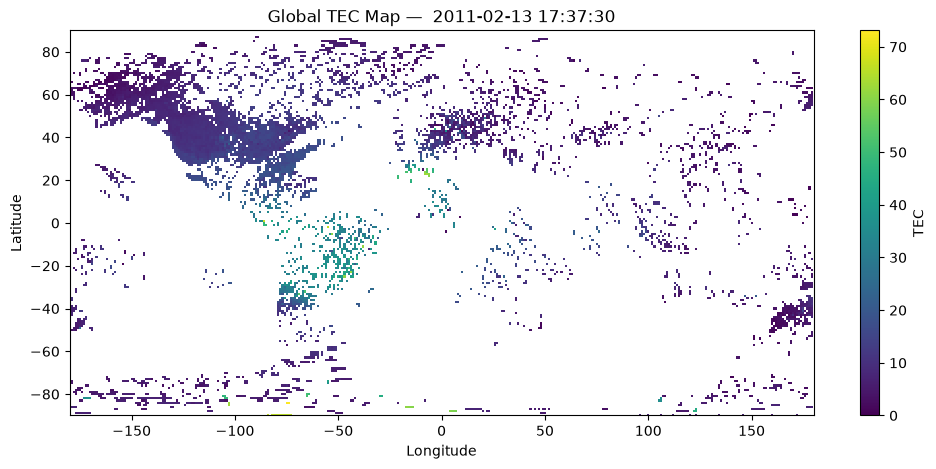

In [ ]:
# plot_map(tec_map,tec_time)

In [17]:
for flare in selected_flares:
    peak = pd.to_datetime(flare["peak_time"])

    for offset in [-3,-2, -1, 0, 1, 2, 3]:
        target_time = peak + pd.Timedelta(hours=offset)

        tec_time, tec_map = extract_nearest_tec_map(target_time)

        plot_map(tec_map, tec_time)

Requested: 2011-02-13 14:38:00
Nearest TEC map: 2011-02-13 14:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_143730.png
Requested: 2011-02-13 15:38:00
Nearest TEC map: 2011-02-13 15:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_153730.png
Requested: 2011-02-13 16:38:00
Nearest TEC map: 2011-02-13 16:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_163730.png
Requested: 2011-02-13 17:38:00
Nearest TEC map: 2011-02-13 17:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_173730.png
Requested: 2011-02-13 18:38:00
Nearest TEC map: 2011-02-13 18:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_183730.png
Requested: 2011-02-13 19:38:00
Nearest TEC map: 2011-02-13 19:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_193730.png
Requested: 2011-02-13 20:38:00
Nearest TEC map: 2011-02-13 20:37:30
Difference: 0 days 00:00:30
Saved: figures/tec_maps/tec_20110213_203

## Covering missing dates

In [7]:
required_dates = {
    (pd.to_datetime(flare["peak_time"]) + pd.Timedelta(hours = offset)).date()
    for flare in selected_flares
    for offset in range(-3,4)
}

available_dates = {
    pd.to_datetime(path.name[3:9], format="%y%m%d").date()
    for path in TEC_DIR.glob("gps*g.*.hdf5")
}

missing_dates = sorted(required_dates-available_dates)

print("Required dates:", len(required_dates))
print("Available dates:", len(available_dates))
print("Missing dates:", missing_dates)

Required dates: 35
Available dates: 35
Missing dates: []


In [10]:
dates = [
    date.strftime("%m/%d/%Y")
    for date in missing_dates
]

for date in dates:
    cmd = [
        "globalDownload.py",
        "--verbose",
        "--url=https://cedar.openmadrigal.org/",
        "--outputDir=./tec_hdf5",
        "--user_fullname=Amrit+Madabushi",
        "--user_email=am2699@njit.edu",
        "--user_affiliation=NJIT",
        "--format=hdf5",
        f"--startDate={date}",
        f"--endDate={date}",
        "--inst=8000",
        "--kindat=3500"
    ]

    print(f"Downloading TEC for {date}")
    subprocess.run(cmd, check=True)

Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/13feb11
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/14feb11
2 files being downloaded
Downloaded file ./tec_hdf5/gps110213g.002_0.hdf5
Downloaded file ./tec_hdf5/gps110214g.003.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/09mar11
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/10mar11
2 files being downloaded
Downloaded file ./tec_hdf5/gps110309g.003_0.hdf5
Downloaded file ./tec_hdf5/gps110310g.002.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/28jul11
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/29jul11
2 files being downloaded
Downloaded file ./tec_hdf5/gps110728g.001.hdf5
Downloaded file ./tec_hdf5/gps110729g.001.hdf5
Analyzed exp url https://cedar.openmadrigal.org/madtoc/experiments3/2011/gps/04sep11
Analyzed exp url https://cedar.openmadrigal.

In [8]:
from pathlib import Path
import pandas as pd

TEC_DIR = Path("tec_hdf5")

extra_files = []

for path in TEC_DIR.glob("*.hdf5"):
    file_date = pd.to_datetime(
        path.name[3:9], format="%y%m%d"
    ).date()

    if file_date not in required_dates or "_0.hdf5" in path.name:
        extra_files.append(path)

print("Extra files:")
for path in extra_files:
    print(path.name)

Extra files:


## Obtain T-4 solar observations from Amazon S3 Nasa Surya Bench

In [9]:
import boto3
from botocore import UNSIGNED

In [10]:
config = boto3.session.Config(signature_version=UNSIGNED)
s3 = boto3.client("s3", config=config)
bucket = 'nasa-surya-bench'

In [33]:
response = s3.list_objects_v2(Bucket=bucket)
for obj in response.get('Contents', []):
    print(obj['Key'])

2010/05/20100513_0012.nc
2010/05/20100513_0024.nc
2010/05/20100513_0036.nc
2010/05/20100513_0048.nc
2010/05/20100513_0100.nc
2010/05/20100513_0112.nc
2010/05/20100513_0124.nc
2010/05/20100513_0136.nc
2010/05/20100513_0148.nc
2010/05/20100513_0200.nc
2010/05/20100513_0212.nc
2010/05/20100513_0224.nc
2010/05/20100513_0236.nc
2010/05/20100513_0248.nc
2010/05/20100513_0300.nc
2010/05/20100513_0312.nc
2010/05/20100513_0324.nc
2010/05/20100513_0336.nc
2010/05/20100513_0348.nc
2010/05/20100513_0400.nc
2010/05/20100513_0412.nc
2010/05/20100513_0424.nc
2010/05/20100513_0436.nc
2010/05/20100513_0448.nc
2010/05/20100513_0500.nc
2010/05/20100513_0512.nc
2010/05/20100513_0524.nc
2010/05/20100513_0536.nc
2010/05/20100513_0548.nc
2010/05/20100513_0600.nc
2010/05/20100513_0612.nc
2010/05/20100513_0624.nc
2010/05/20100513_0636.nc
2010/05/20100513_0648.nc
2010/05/20100513_0700.nc
2010/05/20100513_0712.nc
2010/05/20100513_0724.nc
2010/05/20100513_0736.nc
2010/05/20100513_0748.nc
2010/05/20100513_0800.nc


In [37]:
dates

['01/07/2014',
 '01/23/2012',
 '02/13/2011',
 '02/15/2011',
 '03/07/2012',
 '03/09/2011',
 '03/09/2012',
 '03/10/2012',
 '03/29/2014',
 '04/11/2013',
 '04/25/2014',
 '05/10/2012',
 '07/02/2012',
 '07/04/2012',
 '07/05/2012',
 '07/12/2012',
 '07/30/2011',
 '08/03/2011',
 '08/04/2011',
 '09/06/2011',
 '09/07/2011',
 '09/08/2011',
 '09/10/2014',
 '09/25/2011',
 '10/22/2014',
 '10/24/2014',
 '11/08/2013',
 '11/10/2013']

In [10]:
from datetime import datetime

for date_str in dates:
    date = datetime.strptime(date_str, "%m/%d/%Y")
    prefix = date.strftime("%Y/%m/%Y%m%d_")

    response = s3.list_objects_v2(
        Bucket=bucket,
        Prefix=prefix
    )

    print(date_str, len(response.get("Contents", [])))

01/07/2014 118
01/23/2012 120
02/13/2011 120
02/15/2011 119
03/07/2012 102
03/09/2011 116
03/09/2012 107
03/10/2012 107
03/29/2014 119
04/11/2013 119
04/25/2014 120
05/10/2012 120
07/02/2012 120
07/04/2012 120
07/05/2012 120
07/12/2012 118
07/30/2011 119
08/03/2011 118
08/04/2011 120
09/06/2011 120
09/07/2011 119
09/08/2011 119
09/10/2014 78
09/25/2011 107
10/22/2014 116
10/24/2014 109
11/08/2013 120
11/10/2013 120


In [42]:
for flare in selected_flares:
    print(flare["peak_time"])

2011-02-13 17:38:00
2011-07-30 02:09:00
2011-08-03 13:48:00
2011-08-04 03:57:00
2011-09-06 01:50:00
2011-09-08 15:46:00
2011-09-25 04:50:00
2012-01-23 03:59:00
2012-03-09 03:53:00
2012-03-10 17:44:00
2012-05-10 04:18:00
2012-07-02 10:52:00
2012-07-04 09:55:00
2012-07-05 11:44:00
2013-04-11 07:16:00
2011-02-15 01:56:00
2011-03-09 23:23:00
2011-09-06 22:20:00
2011-09-07 22:38:00
2012-03-07 00:24:00
2012-03-07 01:14:00
2012-07-12 16:49:00
2013-11-08 04:26:00
2013-11-10 05:14:00
2014-01-07 18:32:00
2014-03-29 17:48:00
2014-04-25 00:27:00
2014-09-10 17:45:00
2014-10-22 14:28:00
2014-10-24 21:41:00


In [45]:
for flare in selected_flares:
    peak = pd.to_datetime(flare["peak_time"])
    cutoff = peak-pd.Timedelta(hours=4)
    print(f"Peak: {peak} Cutoff: {cutoff}")

Peak: 2011-02-13 17:38:00 Cutoff: 2011-02-13 13:38:00
Peak: 2011-07-30 02:09:00 Cutoff: 2011-07-29 22:09:00
Peak: 2011-08-03 13:48:00 Cutoff: 2011-08-03 09:48:00
Peak: 2011-08-04 03:57:00 Cutoff: 2011-08-03 23:57:00
Peak: 2011-09-06 01:50:00 Cutoff: 2011-09-05 21:50:00
Peak: 2011-09-08 15:46:00 Cutoff: 2011-09-08 11:46:00
Peak: 2011-09-25 04:50:00 Cutoff: 2011-09-25 00:50:00
Peak: 2012-01-23 03:59:00 Cutoff: 2012-01-22 23:59:00
Peak: 2012-03-09 03:53:00 Cutoff: 2012-03-08 23:53:00
Peak: 2012-03-10 17:44:00 Cutoff: 2012-03-10 13:44:00
Peak: 2012-05-10 04:18:00 Cutoff: 2012-05-10 00:18:00
Peak: 2012-07-02 10:52:00 Cutoff: 2012-07-02 06:52:00
Peak: 2012-07-04 09:55:00 Cutoff: 2012-07-04 05:55:00
Peak: 2012-07-05 11:44:00 Cutoff: 2012-07-05 07:44:00
Peak: 2013-04-11 07:16:00 Cutoff: 2013-04-11 03:16:00
Peak: 2011-02-15 01:56:00 Cutoff: 2011-02-14 21:56:00
Peak: 2011-03-09 23:23:00 Cutoff: 2011-03-09 19:23:00
Peak: 2011-09-06 22:20:00 Cutoff: 2011-09-06 18:20:00
Peak: 2011-09-07 22:38:00 Cu

In [46]:
responses = []
for flare in selected_flares:
    peak = pd.to_datetime(flare["peak_time"])
    cutoff = peak-pd.Timedelta(hours=4)
    prefix = cutoff.strftime("%Y/%m/%Y%m%d_")
    response = s3.list_objects_v2(
        Bucket=bucket,
        Prefix=prefix
    )

    keys = [obj["Key"] for obj in response.get("Contents", [])]

    valid_keys = [
        key for key in keys
        if pd.to_datetime(key.split("/")[-1], format="%Y%m%d_%H%M.nc") <= cutoff
    ]

    if not valid_keys:
        print(f"No valid observation found for {peak}")
        continue

    selected_key = max(valid_keys)

    responses.append((peak,cutoff,selected_key))

    print(date_str, len(response.get("Contents", [])))
    print(f"Peak: {peak} | Cutoff: {cutoff} | S3: {selected_key}")

11/10/2013 120
Peak: 2011-02-13 17:38:00 | Cutoff: 2011-02-13 13:38:00 | S3: 2011/02/20110213_1336.nc
11/10/2013 120
Peak: 2011-07-30 02:09:00 | Cutoff: 2011-07-29 22:09:00 | S3: 2011/07/20110729_2200.nc
11/10/2013 118
Peak: 2011-08-03 13:48:00 | Cutoff: 2011-08-03 09:48:00 | S3: 2011/08/20110803_0948.nc
11/10/2013 118
Peak: 2011-08-04 03:57:00 | Cutoff: 2011-08-03 23:57:00 | S3: 2011/08/20110803_2348.nc
11/10/2013 120
Peak: 2011-09-06 01:50:00 | Cutoff: 2011-09-05 21:50:00 | S3: 2011/09/20110905_2148.nc
11/10/2013 119
Peak: 2011-09-08 15:46:00 | Cutoff: 2011-09-08 11:46:00 | S3: 2011/09/20110908_1136.nc
11/10/2013 107
Peak: 2011-09-25 04:50:00 | Cutoff: 2011-09-25 00:50:00 | S3: 2011/09/20110925_0048.nc
11/10/2013 120
Peak: 2012-01-23 03:59:00 | Cutoff: 2012-01-22 23:59:00 | S3: 2012/01/20120122_2348.nc
11/10/2013 107
Peak: 2012-03-09 03:53:00 | Cutoff: 2012-03-08 23:53:00 | S3: 2012/03/20120308_2348.nc
11/10/2013 107
Peak: 2012-03-10 17:44:00 | Cutoff: 2012-03-10 13:44:00 | S3: 2012/

Note: September 10, 2014 measurement has a temporal difference of 45 mins between the selected flare observation and cutoff

In [11]:
from pathlib import Path

output_dir = Path("solar_observations")
output_dir.mkdir(exist_ok=True)

In [12]:
for peak,cutoff,key in responses:
    destination = output_dir / Path(key).name

    if not destination.exists(): # avoid redownloading
        s3.download_file(bucket, key, str(destination))

    print(f"Downloaded: {destination}")

NameError: name 'responses' is not defined

In [9]:
from pathlib import Path

solar_files = sorted(Path("solar_observations").glob("*.nc"))

print(f"Total solar files: {len(solar_files)}")

for file in solar_files:
    print(file.name)

Total solar files: 30
20110213_1336.nc
20110214_2148.nc
20110309_1900.nc
20110729_2200.nc
20110803_0948.nc
20110803_2348.nc
20110905_2148.nc
20110906_1812.nc
20110907_1836.nc
20110908_1136.nc
20110925_0048.nc
20120122_2348.nc
20120306_2024.nc
20120306_2112.nc
20120308_2348.nc
20120310_1336.nc
20120510_0012.nc
20120702_0648.nc
20120704_0548.nc
20120705_0736.nc
20120712_1248.nc
20130411_0312.nc
20131108_0024.nc
20131110_0112.nc
20140107_1424.nc
20140329_1348.nc
20140424_2024.nc
20140910_1300.nc
20141022_1024.nc
20141024_1736.nc


In [12]:
for flare in selected_flares:    
    peak = pd.to_datetime(flare["peak_time"])
    cutoff = peak-pd.Timedelta(hours=5)
    prefix = cutoff.strftime("%Y/%m/%Y%m%d_")
    response = s3.list_objects_v2(
        Bucket=bucket,
        Prefix=prefix
    )

    keys = [obj["Key"] for obj in response.get("Contents", [])]

    valid_keys = [
        key for key in keys
        if pd.to_datetime(key.split("/")[-1], format="%Y%m%d_%H%M.nc") <= cutoff
    ]

    if not valid_keys:
        print(f"No valid observation found for {peak}")
        continue

    selected_key = max(valid_keys)
    destination = output_dir / Path(selected_key).name
    if not destination.exists():
        s3.download_file(bucket, selected_key, str(destination))
        print(f"Downloaded: {destination.name}")


In [12]:
from pathlib import Path

solar_files = list(Path("solar_observations").glob("*.nc"))

print(f"Total files: {len(solar_files)}")
print(f"Total size: {sum(f.stat().st_size for f in solar_files) / 1024**3:.2f} GiB")

Total files: 60
Total size: 32.60 GiB


In [ ]:
for flare in selected_flares:
    peak = pd.to_datetime(flare["peak_time"])
    cutoff = peak - pd.Timedelta(hours=5)

    candidates = []

    for path in output_dir.glob("*.nc"):
        observation_time = pd.to_datetime(
            path.stem,
            format="%Y%m%d_%H%M"
        )

        if observation_time <= cutoff:
            candidates.append((observation_time, path.name))

    if candidates:
        observation_time, filename = max(candidates)
        difference = (cutoff - observation_time).total_seconds() / 60

        print(
            f"Peak: {peak} | "
            f"T-5 Cutoff: {cutoff} | "
            f"Selected: {observation_time} | "
            f"Difference: {difference:.0f} min | "
            f"File: {filename}"
        )

Peak: 2011-02-13 17:38:00 | T-5 Cutoff: 2011-02-13 12:38:00 | Selected: 2011-02-13 12:36:00 | Difference: 2 min | File: 20110213_1236.nc
Peak: 2011-07-30 02:09:00 | T-5 Cutoff: 2011-07-29 21:09:00 | Selected: 2011-07-29 21:00:00 | Difference: 9 min | File: 20110729_2100.nc
Peak: 2011-08-03 13:48:00 | T-5 Cutoff: 2011-08-03 08:48:00 | Selected: 2011-08-03 08:48:00 | Difference: 0 min | File: 20110803_0848.nc
Peak: 2011-08-04 03:57:00 | T-5 Cutoff: 2011-08-03 22:57:00 | Selected: 2011-08-03 22:48:00 | Difference: 9 min | File: 20110803_2248.nc
Peak: 2011-09-06 01:50:00 | T-5 Cutoff: 2011-09-05 20:50:00 | Selected: 2011-09-05 20:48:00 | Difference: 2 min | File: 20110905_2048.nc
Peak: 2011-09-08 15:46:00 | T-5 Cutoff: 2011-09-08 10:46:00 | Selected: 2011-09-08 10:36:00 | Difference: 10 min | File: 20110908_1036.nc
Peak: 2011-09-25 04:50:00 | T-5 Cutoff: 2011-09-24 23:50:00 | Selected: 2011-09-24 23:48:00 | Difference: 2 min | File: 20110924_2348.nc
Peak: 2012-01-23 03:59:00 | T-5 Cutoff: 

In [14]:
for flare in selected_flares:
    peak = pd.to_datetime(flare["peak_time"])
    cutoff_t4 = peak - pd.Timedelta(hours=4)
    cutoff_t5 = peak - pd.Timedelta(hours=5)

    candidates_t4 = []
    candidates_t5 = []

    for path in output_dir.glob("*.nc"):
        observation_time = pd.to_datetime(path.stem, format="%Y%m%d_%H%M")

        if observation_time <= cutoff_t4:
            candidates_t4.append((observation_time, path.name))

        if observation_time <= cutoff_t5:
            candidates_t5.append((observation_time, path.name))

    if candidates_t4 and candidates_t5:
        t4, file_t4 = max(candidates_t4)
        t5, file_t5 = max(candidates_t5)

        gap = (t4 - t5).total_seconds() / 60

        print(
            f"Peak: {peak} | "
            f"T-5: {t5} | "
            f"T-4: {t4} | "
            f"Gap: {gap:.0f} min"
        )

Peak: 2011-02-13 17:38:00 | T-5: 2011-02-13 12:36:00 | T-4: 2011-02-13 13:36:00 | Gap: 60 min
Peak: 2011-07-30 02:09:00 | T-5: 2011-07-29 21:00:00 | T-4: 2011-07-29 22:00:00 | Gap: 60 min
Peak: 2011-08-03 13:48:00 | T-5: 2011-08-03 08:48:00 | T-4: 2011-08-03 09:48:00 | Gap: 60 min
Peak: 2011-08-04 03:57:00 | T-5: 2011-08-03 22:48:00 | T-4: 2011-08-03 23:48:00 | Gap: 60 min
Peak: 2011-09-06 01:50:00 | T-5: 2011-09-05 20:48:00 | T-4: 2011-09-05 21:48:00 | Gap: 60 min
Peak: 2011-09-08 15:46:00 | T-5: 2011-09-08 10:36:00 | T-4: 2011-09-08 11:36:00 | Gap: 60 min
Peak: 2011-09-25 04:50:00 | T-5: 2011-09-24 23:48:00 | T-4: 2011-09-25 00:48:00 | Gap: 60 min
Peak: 2012-01-23 03:59:00 | T-5: 2012-01-22 22:48:00 | T-4: 2012-01-22 23:48:00 | Gap: 60 min
Peak: 2012-03-09 03:53:00 | T-5: 2012-03-08 22:48:00 | T-4: 2012-03-08 23:48:00 | Gap: 60 min
Peak: 2012-03-10 17:44:00 | T-5: 2012-03-10 12:36:00 | T-4: 2012-03-10 13:36:00 | Gap: 60 min
Peak: 2012-05-10 04:18:00 | T-5: 2012-05-09 23:12:00 | T-4: 

The gap between $t-5$ and $t-4$ for the September 10, 2014 flare is only 24 minutes, consistent with the previously identified 45-minute offset at $t-4$. The March 9th, 2011 flare a gap of 48 minutes. All other solar observations have a 60 minute gap between $t-4$ and $t-5$

# Loading LoRA Trained Surya

In [13]:
from surya.models.helio_spectformer import HelioSpectFormer
from downstream_examples.solar_flare_forcasting.models import HelioSpectformer2D

/home/amritm/projects/surya-tec-forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/amritm/projects/surya-tec-forecasting/.venv/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [14]:
import yaml

with open ("../Surya/downstream_examples/solar_flare_forcasting/config.yaml","r") as f:
    config = yaml.safe_load(f)


In [15]:
config["model"]["ft_unembedding_type"] = "linear"
config["model"]["ft_out_chans"] = 7

In [16]:
print(config["model"]["model_type"])
print(config["model"]["embed_dim"])
print(config["model"]["time_embedding"])

spectformer
1280
{'type': 'linear', 'n_queries': None, 'time_dim': 2}


In [17]:
import torch

model = HelioSpectformer2D(
    img_size=config["model"]["img_size"],
    patch_size=config["model"]["patch_size"],
    in_chans=config["model"]["in_channels"],
    embed_dim=config["model"]["embed_dim"],
    time_embedding=config["model"]["time_embedding"],
    depth=config["model"]["depth"],
    n_spectral_blocks=config["model"]["spectral_blocks"],
    num_heads=config["model"]["num_heads"],
    mlp_ratio=config["model"]["mlp_ratio"],
    drop_rate=config["model"]["drop_rate"],
    window_size=config["model"]["window_size"],
    dp_rank=config["model"]["dp_rank"],
    learned_flow=config["model"]["learned_flow"],
    use_latitude_in_learned_flow=config["use_latitude_in_learned_flow"],
    init_weights=config["model"]["init_weights"],
    checkpoint_layers=config["model"]["checkpoint_layers"],
    rpe=config["model"]["rpe"],
    finetune=True,
    dtype=torch.float32,
    config=config,
)

In [18]:
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

Parameters: 364.22M


In [19]:
checkpoint = torch.load(
    "../Surya/data/Surya-1.0/surya.366m.v1.pt",
    map_location="cpu",
    weights_only=True
)

model_state = model.state_dict()

filtered_checkpoint = {
            k: v
            for k, v in checkpoint.items()
            if k in model_state and v.shape == model_state[k].shape
}
print(f"Matched: {len(filtered_checkpoint)} / {len(checkpoint)} tensors")

Matched: 157 / 159 tensors


In [20]:
for k, v in checkpoint.items():
    if k not in filtered_checkpoint:
        print(k, v.shape)

unembed.unembed.0.weight torch.Size([3328, 1280, 1, 1])
unembed.unembed.0.bias torch.Size([3328])


In [21]:
# model_state.update(filtered_checkpoint)
model.load_state_dict(filtered_checkpoint, strict=False)

print(torch.equal(
    model.state_dict()["embedding.patch_embed.proj.weight"],
    checkpoint["embedding.patch_embed.proj.weight"]
))

True


In [22]:
for name,module in model.named_modules():
    if isinstance(module, torch.nn.Linear):
        if "attn" in name:
            print(name, module.weight.shape)

backbone.blocks_attention.0.attn.qkv torch.Size([3840, 1280])
backbone.blocks_attention.0.attn.proj torch.Size([1280, 1280])
backbone.blocks_attention.0.attn.to_dynamic_projection torch.Size([64, 1280])
backbone.blocks_attention.1.attn.qkv torch.Size([3840, 1280])
backbone.blocks_attention.1.attn.proj torch.Size([1280, 1280])
backbone.blocks_attention.1.attn.to_dynamic_projection torch.Size([64, 1280])
backbone.blocks_attention.2.attn.qkv torch.Size([3840, 1280])
backbone.blocks_attention.2.attn.proj torch.Size([1280, 1280])
backbone.blocks_attention.2.attn.to_dynamic_projection torch.Size([64, 1280])
backbone.blocks_attention.3.attn.qkv torch.Size([3840, 1280])
backbone.blocks_attention.3.attn.proj torch.Size([1280, 1280])
backbone.blocks_attention.3.attn.to_dynamic_projection torch.Size([64, 1280])
backbone.blocks_attention.4.attn.qkv torch.Size([3840, 1280])
backbone.blocks_attention.4.attn.proj torch.Size([1280, 1280])
backbone.blocks_attention.4.attn.to_dynamic_projection torch.Si

In [23]:
from peft import LoraConfig, get_peft_model

In [24]:
targets = ["q_proj", "v_proj", "k_proj", "out_proj", "fc1", "fc2"]

for target in targets:
    matches = [
        name for name, module in model.named_modules()
        if name.endswith(target) and isinstance(module, torch.nn.Linear)
    ]
    print(f"{target}: {len(matches)} matches")

q_proj: 0 matches
v_proj: 0 matches
k_proj: 0 matches
out_proj: 0 matches
fc1: 10 matches
fc2: 10 matches


```
# Note: We will first test Surya LoRA Config using two out of three linear attention projections (query,key,value and output projections) before testing dynamic projection. 
```

In [25]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["attn.qkv", "attn.proj"],
    lora_dropout=.05,
    bias="none",
)

model = get_peft_model(model, lora_config)

In [26]:
model.print_trainable_parameters()

trainable params: 491,520 || all params: 364,713,984 || trainable%: 0.1348


In [27]:
for name,param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

base_model.model.backbone.blocks_attention.0.attn.qkv.lora_A.default.weight torch.Size([8, 1280])
base_model.model.backbone.blocks_attention.0.attn.qkv.lora_B.default.weight torch.Size([3840, 8])
base_model.model.backbone.blocks_attention.0.attn.proj.lora_A.default.weight torch.Size([8, 1280])
base_model.model.backbone.blocks_attention.0.attn.proj.lora_B.default.weight torch.Size([1280, 8])
base_model.model.backbone.blocks_attention.1.attn.qkv.lora_A.default.weight torch.Size([8, 1280])
base_model.model.backbone.blocks_attention.1.attn.qkv.lora_B.default.weight torch.Size([3840, 8])
base_model.model.backbone.blocks_attention.1.attn.proj.lora_A.default.weight torch.Size([8, 1280])
base_model.model.backbone.blocks_attention.1.attn.proj.lora_B.default.weight torch.Size([1280, 8])
base_model.model.backbone.blocks_attention.2.attn.qkv.lora_A.default.weight torch.Size([8, 1280])
base_model.model.backbone.blocks_attention.2.attn.qkv.lora_B.default.weight torch.Size([3840, 8])
base_model.model

## Training

### 0. Preprocessing

In [34]:
print(selected_flares)

[{'flare_class': 'M6.6', 'start_time': '2011-02-13 17:28:00', 'peak_time': '2011-02-13 17:38:00', 'end_time': '2011-02-13 17:47:00', 'active_region_number': 11158, 'harp_number': 377}, {'flare_class': 'M9.3', 'start_time': '2011-07-30 02:04:00', 'peak_time': '2011-07-30 02:09:00', 'end_time': '2011-07-30 02:12:00', 'active_region_number': 11261, 'harp_number': 750}, {'flare_class': 'M6.0', 'start_time': '2011-08-03 13:17:00', 'peak_time': '2011-08-03 13:48:00', 'end_time': '2011-08-03 14:10:00', 'active_region_number': 11261, 'harp_number': 750}, {'flare_class': 'M9.3', 'start_time': '2011-08-04 03:41:00', 'peak_time': '2011-08-04 03:57:00', 'end_time': '2011-08-04 04:04:00', 'active_region_number': 11261, 'harp_number': 750}, {'flare_class': 'M5.3', 'start_time': '2011-09-06 01:35:00', 'peak_time': '2011-09-06 01:50:00', 'end_time': '2011-09-06 02:05:00', 'active_region_number': 11283, 'harp_number': 833}, {'flare_class': 'M6.7', 'start_time': '2011-09-08 15:32:00', 'peak_time': '2011

In [34]:
tec_files = list(Path("figures/tec_maps").glob("tec_*.png"))

In [38]:
flare_df = pd.DataFrame(selected_flares)
for offset in [-5, -4]:
    flare_df[f"solar_t{offset}"] = None

for offset in range(-3, 4):
    flare_df[f"tec_t{offset:+d}"] = None

solar_times = {
    path: pd.to_datetime(path.stem,format="%Y%m%d_%H%M")
    for path in solar_files
}

tec_times = {
    path: pd.to_datetime(
        path.stem.removeprefix("tec_"),
        format="%Y%m%d_%H%M%S"
    )
    for path in tec_files
}
hdf5_files = list(Path("tec_hdf5").glob("*.hdf5"))
hdf5_by_date = {
    pd.to_datetime(path.name[3:9], format="%y%m%d").date(): path
    for path in hdf5_files
}

In [53]:
with h5py.File("tec_hdf5/gps110213g.002.hdf5", "r") as f:
    dataset = f["Data"]["Table Layout"]

    print(dataset.shape)
    print(dataset.dtype.names)

(1812127,)
('year', 'month', 'day', 'hour', 'min', 'sec', 'recno', 'kindat', 'kinst', 'ut1_unix', 'ut2_unix', 'gdlat', 'glon', 'tec', 'dtec', 'gdalt')


In [1]:
for idx, flare in flare_df.iterrows():
    peak_time = pd.Timestamp(flare["peak_time"])

    # Match existing solar observations to solar_t5 and solar_t4
    for offset in [-5,-4]:
        target_time = peak_time + pd.Timedelta(hours=offset)
        
        closest_file = min(
            solar_times,
            key=lambda path: abs(solar_times[path] - target_time)
        )

        flare_df.at[idx, f"solar_t{offset:+d}"] = str(closest_file)
            
    # Match existing TEC maps to the seven target timestamps
    for offset in range(-3, 4):
        col = f"tec_t{offset:+d}"
        target_time = peak_time + pd.Timedelta(hours=offset)

        closest_file = min(
            tec_times,
            key=lambda path: abs(tec_times[path] - target_time)
        )

        flare_df.at[idx, col] = str(closest_file)

        tec_time = tec_times[closest_file]

        flare_df.at[idx, f"{col}_hdf5"] = str(
            hdf5_by_date.get(tec_time.date(), "")
        )
            
flare_df.to_csv("flare_manifest.csv", index=False)

NameError: name 'flare_df' is not defined

In [16]:
def grid_tec(tec_map, resolution=1.0):
    '''
    This function is used to create a grid based on latitude, longitude and total electron content (TEC) measurements 
    provided by the map.
    
    Longitude coordinates are normalized to [-180, 180], and spatial binning is applied to latitude and longitude. 
    TEC measurements within each grid cell are averaged, with cells containing no valid observations reported as NaN. 
    '''
    lat = tec_map["gdlat"].to_numpy()
    lon = tec_map["glon"].to_numpy()
    tec = tec_map["tec"].to_numpy()

    # Normalize Longitude
    lon = ((lon+180)%360)-180

    # Remove invalid measurements
    valid = (np.isfinite(lat) & np.isfinite(lon) & np.isfinite(tec))

    lat = lat[valid]
    lon = lon[valid]
    tec = tec[valid]

    # Grid boundaries
    if resolution <= 0 or not np.isclose(180 / resolution, round(180 / resolution)):
        raise ValueError("Resolution must evenly divide 180 degrees.")
    lat_edges = np.linspace(-90,90,int(180/resolution)+1)
    lon_edges = np.linspace(-180,180,int(360/resolution)+1)

    # Aggregate TEC values within each grid cell
    tec_sum, _, _ = np.histogram2d(
        lat, lon,
        bins=[lat_edges, lon_edges],
        weights=tec
    )

    # Count meaasurements within each cell
    counts, _, _ = np.histogram2d(
        lat, lon,
        bins=[lat_edges, lon_edges]
    )

    # Calculate mean TEC per cell
    grid = np.full(tec_sum.shape, np.nan, dtype=np.float32)

    np.divide(tec_sum,counts,out=grid,where=counts>0)

    return grid

In [17]:
def extract_nearest_tec_map(target_time, path):
    """
    Extract the TEC map from the hdf5 file
    """
    target_time = pd.to_datetime(target_time)


    nearest_time = None
    nearest_diff = None

    # PASS 1: find nearest avaliable TEC timestamp
    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0,len(table),CHUNK_SIZE):
            chunk = table[start:start+CHUNK_SIZE]

            times = pd.to_datetime({
                "year": chunk["year"],
                "month": chunk["month"],
                "day": chunk["day"],
                "hour": chunk["hour"],
                "minute": chunk["min"],
                "second": chunk["sec"],
            })

            unique_times = pd.Index(times.unique())

            diffs = abs(unique_times-target_time)
            i = diffs.argmin()

            candidate_time = unique_times[i]
            candidate_diff = diffs[i]

            if nearest_diff is None or candidate_diff < nearest_diff:
                nearest_diff = candidate_diff
                nearest_time = candidate_time
        print(f"Requested: {target_time}")
    print(f"Nearest TEC map: {nearest_time}")
    print(f"Difference: {nearest_diff}")
    if nearest_diff > pd.Timedelta(minutes=5):
        raise ValueError(
            f"TEC timestamp mismatch: requested {target_time}, nearest {nearest_time}, difference {nearest_diff}"
        )

    # PASS 2: extract only rows belonging to that TEC timestamp
    pieces = []

    with h5py.File(path, "r") as f:
        table = f["Data"]["Table Layout"]

        for start in range(0, len(table), CHUNK_SIZE):
            chunk = table[start:start + CHUNK_SIZE]

            mask = (
                (chunk["year"] == nearest_time.year) &
                (chunk["month"] == nearest_time.month) &
                (chunk["day"] == nearest_time.day) &
                (chunk["hour"] == nearest_time.hour) &
                (chunk["min"] == nearest_time.minute) &
                (chunk["sec"] == nearest_time.second)
            )

            if np.any(mask):
                selected = chunk[mask]

                pieces.append(
                    pd.DataFrame({
                        "gdlat": selected["gdlat"],
                        "glon": selected["glon"],
                        "tec": selected["tec"],
                    })
                )

    if not pieces:
        raise RuntimeError(
            f"No TEC rows found for {nearest_time}"
        )

    tec_map = pd.concat(pieces, ignore_index=True)

    # Madrigal missing-value convention
    tec_map.loc[tec_map["tec"] > 1e20, "tec"] = np.nan

    return nearest_time, tec_map

In [ ]:
# Used to generate the precomputed TEC Grids stored in npz files instead of accessing from hdf5 files
# from pathlib import Path

# output_dir = Path("tec_grids")
# output_dir.mkdir(exist_ok=True)

# for idx,flare in dataset.df.iterrows():
#     tec, tec_mask = dataset.load_tec(flare)

#     output_path = output_dir / f"flare_{idx:03d}.npz"

#     np.savez_compressed(
#         output_path,
#         tec=tec,
#         tec_mask = tec_mask,
#         resolution=1.0
#     )
#     dataset.df.loc[idx, "tec_grid_path"] = str(output_path)


# dataset.df.to_csv("flare_manifest.csv", index=False)

Requested: 2011-02-13 14:38:00
Nearest TEC map: 2011-02-13 14:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 15:38:00
Nearest TEC map: 2011-02-13 15:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 16:38:00
Nearest TEC map: 2011-02-13 16:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 17:38:00
Nearest TEC map: 2011-02-13 17:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 18:38:00
Nearest TEC map: 2011-02-13 18:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 19:38:00
Nearest TEC map: 2011-02-13 19:37:30
Difference: 0 days 00:00:30
Requested: 2011-02-13 20:38:00
Nearest TEC map: 2011-02-13 20:37:30
Difference: 0 days 00:00:30
Requested: 2011-07-29 23:09:00
Nearest TEC map: 2011-07-29 23:07:30
Difference: 0 days 00:01:30
Requested: 2011-07-30 00:09:00
Nearest TEC map: 2011-07-30 00:07:30
Difference: 0 days 00:01:30
Requested: 2011-07-30 01:09:00
Nearest TEC map: 2011-07-30 01:07:30
Difference: 0 days 00:01:30
Requested: 2011-07-30 02:09:00
Nearest T

In [8]:
target_time = pd.Timestamp("2011-02-13 14:38:00")

tec_time, tec_map = extract_nearest_tec_map(target_time)

tec_grid = grid_tec(tec_map)

print("Timestamp:", tec_time)
print("Grid shape:", tec_grid.shape)
print("Valid cells:", np.isfinite(tec_grid).sum())
print("Missing cells:", np.isnan(tec_grid).sum())

Requested: 2011-02-13 14:38:00
Nearest TEC map: 2011-02-13 14:37:30
Difference: 0 days 00:00:30
Timestamp: 2011-02-13 14:37:30
Grid shape: (180, 360)
Valid cells: 6514
Missing cells: 58286


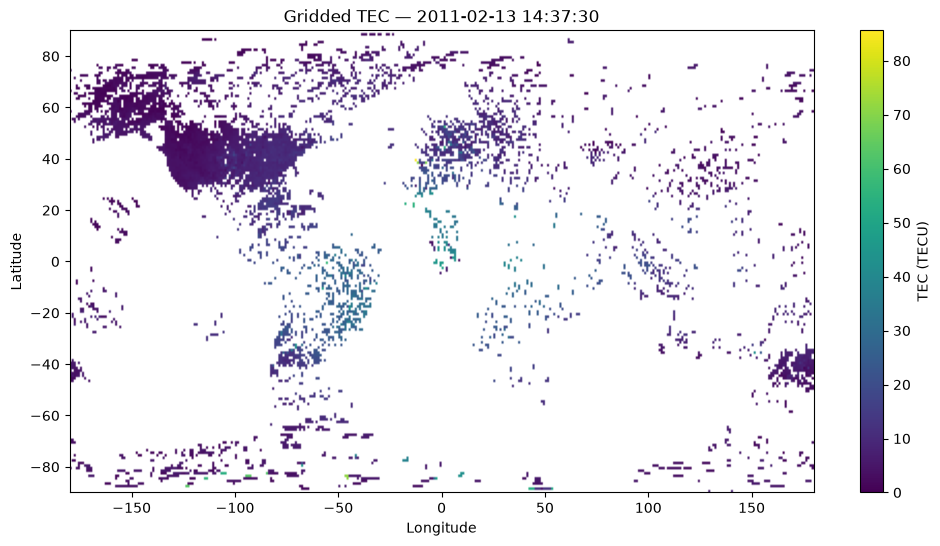

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.imshow(
    tec_grid,
    origin="lower",
    extent=[-180, 180, -90, 90],
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="TEC (TECU)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Gridded TEC — {tec_time}")

plt.show()

In [15]:
for resolution in [0.5, 1.0, 2.0]:
    grid = grid_tec(tec_map, resolution=resolution)

    coverage = np.isfinite(grid).mean() * 100

    print(
        f"Resolution: {resolution}° | "
        f"Shape: {grid.shape} | "
        f"Coverage: {coverage:.2f}%"
    )

Resolution: 0.5° | Shape: (360, 720) | Coverage: 2.51%
Resolution: 1.0° | Shape: (180, 360) | Coverage: 10.05%
Resolution: 2.0° | Shape: (90, 180) | Coverage: 20.25%


Load scalers from Surya (Normalize into shape $X\in{R^{13*2*4096*4096}}$ )

In [27]:
import pandas as pd
from torch.utils.data import Dataset
import yaml
from surya.utils.data import build_scalers
from surya.datasets.helio import transform
import numpy as np
import xarray as xr
import torch

class FlareDataset(Dataset):
    def __init__(self,manifest_path):
        self.df = pd.read_csv(manifest_path)
        with open("../Surya/data/Surya-1.0/scalers.yaml") as f:
            scaler_info = yaml.safe_load(f)

        scalers = build_scalers(scaler_info)
        self.channels = [
            "aia94", "aia131", "aia171", "aia193",
            "aia211", "aia304", "aia335", "aia1600",
            "hmi_m", "hmi_bx", "hmi_by", "hmi_bz", "hmi_v"
        ]
        self.means = np.array([scalers[ch].mean for ch in self.channels])
        self.stds = np.array([scalers[ch].std for ch in self.channels])
        self.scale_factors = np.array([scalers[ch].sl_scale_factor for ch in self.channels])
        self.epsilons = np.array([scalers[ch].epsilon for ch in self.channels])


    def __len__(self):
        return len(self.df)
    def load_solar(self, path):
        with xr.open_dataset(
            path,
            engine="h5netcdf",
            chunks=None,
            cache=False
        ) as ds:
            solar = ds[self.channels].to_array().load().to_numpy()

        return transform(
            solar,
            self.means,
            self.stds,
            self.scale_factors,
            self.epsilons
        )
    def load_tec(self, path):        
        with np.load(path) as data:
            tec = data["tec"]
            tec_mask = data["tec_mask"]

        return tec, tec_mask
    
        # OLD
        # peak_time = pd.Timestamp(flare["peak_time"])
        # tec_grids = []

        # for offset in range(-3,4):
        #     label = f"tec_t{offset:+d}"

        #     path = flare[f"{label}_hdf5"]
        #     target_time = peak_time + pd.Timedelta(hours=offset)

        #     _,tec_map = extract_nearest_tec_map(target_time, path)

        #     tec_grid = grid_tec(tec_map, resolution=1.0)
        #     tec_grids.append(tec_grid)

        # tec = np.stack(tec_grids,axis=0)

        # tec_mask = np.isfinite(tec)
        # tec = np.nan_to_num(tec,nan=0.0).astype(np.float32)

        # return tec,tec_mask


    def __getitem__(self, idx):
        flare = self.df.iloc[idx]

        solar_t5 = self.load_solar(flare["solar_t-5"])
        solar_t4 = self.load_solar(flare["solar_t-4"])

        solar = np.stack([solar_t5, solar_t4], axis=1)
        tec, tec_mask = self.load_tec(flare["tec_grid_path"])

        return {
            "solar": torch.from_numpy(solar),
            "tec": torch.from_numpy(tec),
            "tec_mask": torch.from_numpy(tec_mask),
            "flare_class": flare["flare_class"],
            "peak_time": flare["peak_time"]
        }
    def get_flares_by_class(self, flare_class):
        return self.df[self.df["flare_class"] == flare_class]

In [28]:
dataset = FlareDataset("flare_manifest.csv")


In [29]:
print(len(dataset))

sample = dataset[0]

print(sample["solar"].shape)
print(sample["solar"].dtype)
print(torch.isfinite(sample["solar"]).all())

30
torch.Size([13, 2, 4096, 4096])
torch.float32
tensor(True)


In [30]:
flare15 = dataset.__getitem__(idx=15)
flare15

{'solar': tensor([[[[-2.7955e-01, -4.5286e-01, -4.7089e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.4036e-01],
           [-3.6507e-01, -3.1025e-01, -4.9601e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.4036e-01],
           [-3.9150e-01, -2.9382e-01, -4.9627e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.4036e-01],
           ...,
           [-4.5121e-01, -4.4202e-01, -3.7811e-01,  ..., -2.0305e-01,
            -2.0305e-01, -5.4036e-01],
           [-3.8197e-01, -3.4819e-01, -3.7878e-01,  ..., -1.1571e-01,
            -1.7886e-01, -5.4036e-01],
           [-5.4036e-01, -1.4429e-01, -4.5878e-01,  ..., -1.1571e-01,
            -1.7886e-01, -5.4036e-01]],
 
          [[-4.4656e-01, -2.9547e-01, -2.9696e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.4036e-01],
           [-4.9893e-01, -5.4036e-01, -5.4036e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.4036e-01],
           [-4.9165e-01, -5.4036e-01, -4.2959e-01,  ..., -5.4036e-01,
            -5.4036e-01, -5.40

In [31]:
# Inspect Flares according to class
dataset.get_flares_by_class("M9.3")

,flare_class,start_time,peak_time,end_time,active_region_number,harp_number,solar_t-5,solar_t-4,tec_t-3,tec_t-2,...,tec_t+2,tec_t+3,tec_t-3_hdf5,tec_t-2_hdf5,tec_t-1_hdf5,tec_t+0_hdf5,tec_t+1_hdf5,tec_t+2_hdf5,tec_t+3_hdf5,tec_grid_path
1,M9.3,2011-07-30 02:04:00,2011-07-30 02:09:00,2011-07-30 02:12:00,11261,750,solar_observations/20110729_2100.nc,solar_observations/20110729_2200.nc,figures/tec_maps/tec_20110729_230730.png,figures/tec_maps/tec_20110730_000730.png,...,figures/tec_maps/tec_20110730_040730.png,figures/tec_maps/tec_20110730_050730.png,tec_hdf5/gps110729g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_hdf5/gps110730g.001.hdf5,tec_grids/flare_001.npz
3,M9.3,2011-08-04 03:41:00,2011-08-04 03:57:00,2011-08-04 04:04:00,11261,750,solar_observations/20110803_2248.nc,solar_observations/20110803_2348.nc,figures/tec_maps/tec_20110804_005730.png,figures/tec_maps/tec_20110804_015730.png,...,figures/tec_maps/tec_20110804_055730.png,figures/tec_maps/tec_20110804_065730.png,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_hdf5/gps110804g.002.hdf5,tec_grids/flare_003.npz


$TEC_{i,j} = \frac{1}{N_{i,j}}\sum_{k\in{B_{i,j}}}{TEC_k}$

For this experiment, we will be using 1.0° resolution.

### 1. Training

Input: $ X \in \mathbb{R}^{13*2*4096*4096}$

Predictions: $\hat{Y} \in \mathbb{R}^{7*180*360}$

$\mathcal{L}_{masked MSE} = \frac{\sum_{t,i,j}{M_{t,i,j}(\hat{Y}_{t,i,j}-Y_{t,i,j})^2}}{\sum_{t,i,j}{M_{t,i,j}}}$

In [ ]:
# TODO: CONFIGURE SURYA LORA TRAINED MODEL WITH DATASET